# ConjunctivaGuard PoC, Part 5: quality scores (M3) and the baseline anemia model (M4)

**Goal**
1. Measure photo quality **on the eyelid only**, with the sharpness problem from Part 4 fixed.
2. Train a **baseline** anemia model (EfficientNet-B0) on clean training photos.
3. Test it on clean **and** damaged photos: how much worse does it get as damage grows? (a first look at experiment E1 / RQ1)

**Turn on the GPU:** Runtime → Change runtime type → **T4 GPU** → Save. Run the cells top to bottom. About 20 minutes.

### Cell 1: setup
Gets D01 again and reads two files from earlier parts: the **split** (Part 2) and the **damaged-photo list** (Part 4).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile, gdown, json
import numpy as np, pandas as pd, torch

D01_LINK_ID = 'YOUR_D01_FILE_ID'
OUT = '/content/drive/MyDrive/ConjunctivaGuard/poc_outputs'
if not os.path.exists('/content/D01.zip'):
    gdown.download(id=D01_LINK_ID, output='/content/D01.zip', quiet=True)
if not os.path.exists('/content/work/D01'):
    with zipfile.ZipFile('/content/D01.zip') as zf:
        zf.extractall('/content/work/D01')
D01_DIR = glob.glob('/content/work/D01/*/')[0]

splits = pd.read_csv(os.path.join(OUT, 'D01_splits.csv'))
man = pd.read_csv(os.path.join(OUT, 'D04_poc_manifest.csv'))
print('GPU available:', torch.cuda.is_available())
print('Training photos (clean):', int(((splits.split == 'train') & splits.keep).sum()))
print('Val / test images (clean + damaged):', int((man.split == 'val').sum()), '/', int((man.split == 'test').sum()))

Mounted at /content/drive
GPU available: True
Training photos (clean): 1467
Val / test images (clean + damaged): 600 / 750


### Cell 2: the quality tools (M3, first version)
Three numbers, measured **only on the eyelid**:

| Number | What it means | Fixed since Part 4 |
|---|---|---|
| `glare_share` | part of the eyelid that is almost white and colourless | also checks "colourless", so pale pink is not called glare |
| `brightness` | average lightness of the eyelid, 0 (black) to 100 (white) | glare pixels are left out |
| `sharpness` | how strong the fine edges are | grain is smoothed and its share subtracted, the value is divided by brightness, and glare edges are skipped |

In [ ]:
import numpy as np
import cv2
from PIL import Image

def _grain_constants():
    # how pure grain (random dots) shows up in our measurements, worked out once on fake noise
    n = np.random.default_rng(0).normal(0, 1, (256, 256)).astype(np.float32)
    hp = n - cv2.GaussianBlur(n, (0, 0), 1.0)
    s = cv2.GaussianBlur(n, (0, 0), 1.5)
    g2 = cv2.Sobel(s, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(s, cv2.CV_32F, 0, 1) ** 2
    return float(np.median(np.abs(hp)) * 1.4826), float(g2[8:-8, 8:-8].mean())
GRAIN_HP, GRAIN_GRAD = _grain_constants()

def load_rgba(path):
    im = np.asarray(Image.open(path).convert('RGBA'))
    return im[..., :3], im[..., 3] > 0

def quality_profile(rgb, tissue):
    # M3 (first version): three numbers measured ONLY on the eyelid
    rgb = rgb.astype(np.uint8)
    t = tissue.astype(bool)
    area = max(int(t.sum()), 1)
    # 1) glare: almost-white, almost-colourless pixels on the eyelid
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    glare = t & (rgb.min(axis=2) > 225) & (hsv[..., 1] < 40)
    glare_share = glare.sum() / area
    # 2) brightness: average lightness (0-100) of the eyelid, glare left out
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    good = t & ~glare
    if good.sum() < 20:
        good = t
    brightness = float(lab[..., 0][good].mean()) * 100 / 255
    # 3) sharpness: smooth away grain, measure how strong the edges are,
    #    divide by brightness (so darkness alone does not change it), and
    #    skip the glare area and the cut-out edge
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    smooth = cv2.GaussianBlur(gray, (0, 0), 1.5)
    gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1)
    inner = cv2.erode(t.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0
    near_glare = cv2.dilate(glare.astype(np.uint8), np.ones((11, 11), np.uint8)) > 0
    zone = inner & ~near_glare
    if zone.sum() < 30:
        sharpness = float('nan')
    else:
        hp = gray - cv2.GaussianBlur(gray, (0, 0), 1.0)
        grain = float(np.median(np.abs(hp[zone])) * 1.4826) / GRAIN_HP      # how grainy this photo is
        energy = (gx ** 2 + gy ** 2)[zone].mean() - GRAIN_GRAD * grain ** 2  # remove the grain's share
        sharpness = float(np.sqrt(max(energy, 0.0)) / (smooth[zone].mean() + 1e-6) * 100)
    return {'glare_share': float(glare_share), 'brightness': brightness, 'sharpness': sharpness}


### Cell 3: did the fix work?
Quality of every val / test image. Each number is shown as % of the **same eyelid's clean photo** (clean = 100%). Now each number should react **only to its own damage**:
- glare share goes up only for glare,
- brightness goes down only for dark,
- sharpness goes down only for blur (in Part 4 it wrongly went **up** for dark and glare).

In [ ]:
from tqdm.auto import tqdm

q = [quality_profile(*load_rgba(p)) for p in tqdm(man.path)]
man = pd.concat([man.drop(columns=['brightness', 'sharpness', 'glare_share'], errors='ignore'),
                 pd.DataFrame(q)], axis=1)

t = man[man.split == 'test'].copy()
clean = t[t.damage == 'none'].set_index('file')
for m in ('brightness', 'sharpness'):
    t[m + '_%'] = (100 * t[m] / t.file.map(clean[m])).replace([np.inf, -np.inf], np.nan)
order = pd.MultiIndex.from_product([['glare', 'blur', 'dark'], ['mild', 'moderate', 'severe']])
display(t[t.damage != 'none'].groupby(['damage', 'level'])[['glare_share', 'brightness_%', 'sharpness_%']]
        .mean().reindex(order).round(2))

  0%|          | 0/1350 [00:00<?, ?it/s]

glare_share  brightness_%  sharpness_%
glare mild             0.04        100.47        99.11
      moderate         0.14        101.13       100.76
      severe           0.29        100.83       100.41
blur  mild             0.00         99.68        96.43
      moderate         0.00         99.68        86.58
      severe           0.00         99.65        67.42
dark  mild             0.00         75.66       101.71
      moderate         0.00         50.24       101.51
      severe           0.00         28.56       100.80

### Cell 4: prepare photos for the model
The model needs every picture the same size, so each eyelid strip is placed on a black square and resized to **224 × 224**.

Training uses the clean **train** photos (including the dataset's own rotated copies). We do **not** change colours during training, because colour is exactly the anemia signal.

In [ ]:
from PIL import Image

SIZE = 224
def to_input(path):
    im = np.asarray(Image.open(path).convert('RGBA'))
    rgb = im[..., :3].copy(); rgb[im[..., 3] == 0] = 0                 # empty background = black
    h, w = rgb.shape[:2]; s = max(h, w)
    sq = np.zeros((s, s, 3), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = rgb
    return np.asarray(Image.fromarray(sq).resize((SIZE, SIZE), Image.BILINEAR))

tr = splits[(splits.split == 'train') & splits.keep].reset_index(drop=True)
Xtr = np.stack([to_input(os.path.join(D01_DIR, f)) for f in tqdm(tr.file, desc='train')])
ytr = tr.label.values.astype(np.float32)
Xall = np.stack([to_input(p) for p in tqdm(man.path, desc='val + test')])
yall = man.label.values.astype(np.float32)
val_clean = np.where((man.split == 'val') & (man.damage == 'none'))[0]
print('train', Xtr.shape, '| anemic share in train:', round(float(ytr.mean()), 2))

train:   0%|          | 0/1467 [00:00<?, ?it/s]

val + test:   0%|          | 0/1350 [00:00<?, ?it/s]

train (1467, 224, 224, 3) | anemic share in train: 0.56


### Cell 5: train the baseline anemia model (about 5–8 minutes)
**EfficientNet-B0**, pretrained on everyday photos (transfer learning, like Part 3), learns *anemic (1) vs not anemic (0)*. Its output is a **probability** `p` between 0 and 1.

Each line is one epoch. Watch:
- **loss** going down;
- **validation AUROC** (on clean val photos): 0.5 = coin flip, 1.0 = perfect.

The best epoch is saved as `M4_effnet_b0.pt`.

In [ ]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import roc_auc_score

torch.manual_seed(42); np.random.seed(42)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
MEAN = np.array([0.485, 0.456, 0.406], np.float32); STD = np.array([0.229, 0.224, 0.225], np.float32)

class Strips(Dataset):
    def __init__(self, X, y, train):
        self.X, self.y, self.train = X, y, train
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        x = self.X[i].astype(np.float32) / 255.0
        if self.train:                                   # turn / mirror only, never change colour
            x = np.rot90(x, np.random.randint(4))
            if np.random.rand() < 0.5:
                x = x[:, ::-1]
        x = (x - MEAN) / STD
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), torch.tensor([self.y[i]])

model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)
model = model.to(dev)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
lossf = nn.BCEWithLogitsLoss()

def predict(X):
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in DataLoader(Strips(X, np.zeros(len(X), np.float32), False), batch_size=64):
            out.append(torch.sigmoid(model(xb.to(dev))).cpu().numpy()[:, 0])
    return np.concatenate(out)

MODEL_PATH = os.path.join(OUT, 'M4_effnet_b0.pt')
dl = DataLoader(Strips(Xtr, ytr, True), batch_size=32, shuffle=True)
EPOCHS, history, best = 12, [], -1.0
for ep in range(1, EPOCHS + 1):
    model.train(); losses = []
    for xb, yb in dl:
        xb, yb = xb.to(dev), yb.to(dev)
        loss = lossf(model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    pv = predict(Xall[val_clean])
    auc = roc_auc_score(yall[val_clean], pv)
    history.append((ep, float(np.mean(losses)), float(auc)))
    note = ''
    if auc > best:
        best = auc; torch.save(model.state_dict(), MODEL_PATH); note = '  <- best so far, saved'
    print(f'epoch {ep:2d} | loss {np.mean(losses):.3f} | validation AUROC {auc:.3f}{note}')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]


epoch  1 | loss 0.654 | validation AUROC 0.714  <- best so far, saved
epoch  2 | loss 0.544 | validation AUROC 0.725  <- best so far, saved
epoch  3 | loss 0.455 | validation AUROC 0.764  <- best so far, saved
epoch  4 | loss 0.359 | validation AUROC 0.795  <- best so far, saved
epoch  5 | loss 0.319 | validation AUROC 0.851  <- best so far, saved
epoch  6 | loss 0.234 | validation AUROC 0.764
epoch  7 | loss 0.212 | validation AUROC 0.850
epoch  8 | loss 0.158 | validation AUROC 0.730
epoch  9 | loss 0.116 | validation AUROC 0.850
epoch 10 | loss 0.120 | validation AUROC 0.779
epoch 11 | loss 0.139 | validation AUROC 0.803
epoch 12 | loss 0.121 | validation AUROC 0.856  <- best so far, saved


### Cell 6: learning curves

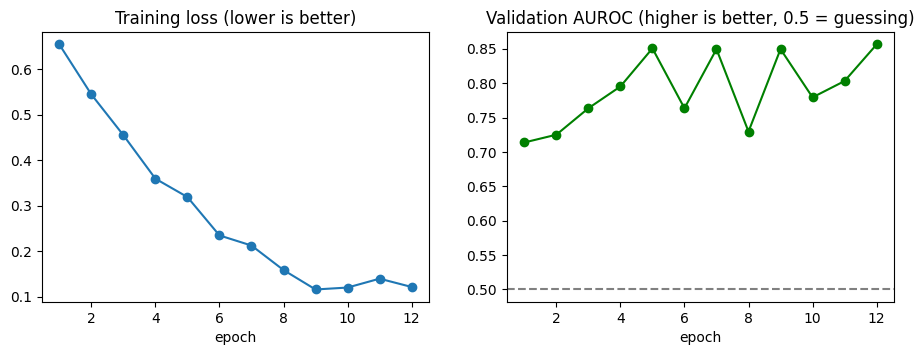

In [ ]:
import matplotlib.pyplot as plt
h = np.array(history)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(h[:, 0], h[:, 1], marker='o'); a.set_title('Training loss (lower is better)'); a.set_xlabel('epoch')
b.plot(h[:, 0], h[:, 2], marker='o', color='green'); b.axhline(0.5, ls='--', color='grey')
b.set_title('Validation AUROC (higher is better, 0.5 = guessing)'); b.set_xlabel('epoch')
plt.show()

### Cell 7: the final exam on clean test photos
Loads the best model and scores the **75 clean test eyelids** it has never seen.

- **AUROC** with a **95% confidence interval** (CI): the range where the true score probably lies. With only 75 test eyelids the range is wide; that is honest, not a mistake. It is found by **bootstrapping**: re-scoring 1,000 random re-draws of the test set.
- **Threshold:** to turn `p` into a yes/no answer we need a cut-off. It is chosen on the **validation** photos (never on test), then used on test.
- **Sensitivity** = share of anemic children found. **Specificity** = share of healthy children correctly cleared.

In [ ]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=dev))
man['p'] = predict(Xall)

def auroc_ci(y, p, n=1000, seed=0):
    if len(set(y)) < 2:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2:
            vals.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(vals, 2.5), np.percentile(vals, 97.5)

v = man[(man.split == 'val') & (man.damage == 'none')]
cands = np.linspace(0.05, 0.95, 91)
bal = [((v.p >= c)[v.label == 1].mean() + (v.p < c)[v.label == 0].mean()) / 2 for c in cands]
THR = float(cands[int(np.argmax(bal))])

tc = man[(man.split == 'test') & (man.damage == 'none')]
auc, lo, hi = auroc_ci(tc.label.values, tc.p.values)
sens = float((tc.p >= THR)[tc.label == 1].mean()); spec = float((tc.p < THR)[tc.label == 0].mean())
print(f'Clean test AUROC: {auc:.3f}  (95% CI {lo:.3f} to {hi:.3f})')
print(f'Threshold chosen on validation: {THR:.2f}')
print(f'Sensitivity {sens:.2f} | Specificity {spec:.2f}  on {len(tc)} test eyelids')

Clean test AUROC: 0.778  (95% CI 0.670 to 0.883)
Threshold chosen on validation: 0.26
Sensitivity 0.81 | Specificity 0.45  on 75 test eyelids


### Cell 8: how much do damaged photos hurt the model? (E1 preview)
Same 75 test eyelids, now damaged. For each damage and level:
- **AUROC** (compare with clean);
- **answers changed**: share of eyelids where the yes/no answer is different from the clean photo's answer. These are the cases where a bad photo would have given a **different result** for the same child, which is exactly what ConjunctivaGuard must catch.

,damage,level,AUROC,AUROC_low,AUROC_high,answers_changed_%
0,none,clean,0.778,0.670,0.883,0.000
1,glare,mild,0.776,0.668,0.876,8.000
2,glare,moderate,0.760,0.645,0.865,29.333
3,glare,severe,0.733,0.618,0.844,34.667
4,blur,mild,0.753,0.636,0.855,12.000
5,blur,moderate,0.708,0.586,0.817,17.333
6,blur,severe,0.612,0.483,0.731,18.667
7,dark,mild,0.690,0.561,0.809,22.667
8,dark,moderate,0.508,0.371,0.642,28.000
9,dark,severe,0.515,0.368,0.646,33.333


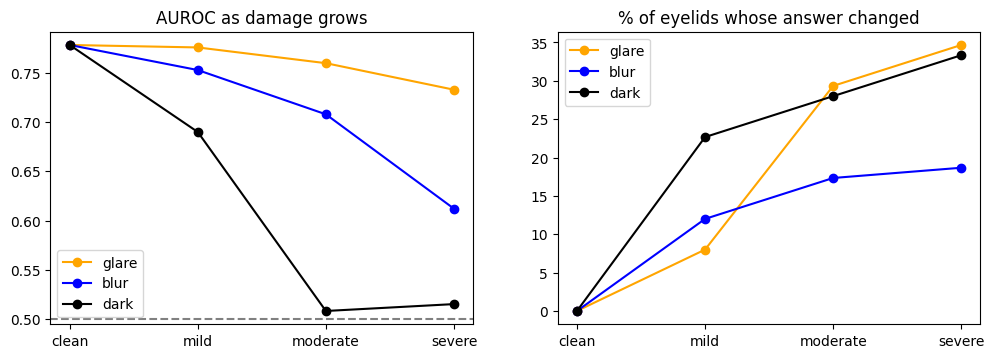

In [ ]:
test = man[man.split == 'test'].copy()
clean_p = test[test.damage == 'none'].set_index('file').p
rows = [{'damage': 'none', 'level': 'clean', 'AUROC': auc, 'AUROC_low': lo, 'AUROC_high': hi, 'answers_changed_%': 0.0}]
for kind in ['glare', 'blur', 'dark']:
    for level in ['mild', 'moderate', 'severe']:
        d = test[(test.damage == kind) & (test.level == level)]
        a, l, h_ = auroc_ci(d.label.values, d.p.values)
        changed = 100 * float(((d.p >= THR).values != (d.file.map(clean_p) >= THR).values).mean())
        rows.append({'damage': kind, 'level': level, 'AUROC': a, 'AUROC_low': l, 'AUROC_high': h_,
                     'answers_changed_%': changed})
effect = pd.DataFrame(rows).round(3)
display(effect)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.8))
xs = ['clean', 'mild', 'moderate', 'severe']
for kind, c in zip(['glare', 'blur', 'dark'], ['orange', 'blue', 'black']):
    e = effect[effect.damage == kind]
    a.plot(xs, [auc] + list(e.AUROC), marker='o', label=kind, color=c)
    b.plot(xs, [0] + list(e['answers_changed_%']), marker='o', label=kind, color=c)
a.axhline(0.5, ls='--', color='grey'); a.set_title('AUROC as damage grows'); a.legend()
b.set_title('% of eyelids whose answer changed'); b.legend()
plt.show()

### Cell 9: save everything
Saves every prediction with its quality numbers (Part 6 uses this file) and a short results summary.

In [ ]:
keep = ['file', 'group', 'label', 'split', 'damage', 'level', 'path', 'p', 'glare_share', 'brightness', 'sharpness']
man[keep].to_csv(os.path.join(OUT, 'M4_predictions.csv'), index=False)
effect.to_csv(os.path.join(OUT, 'E1_preview_damage_effect.csv'), index=False)
pd.DataFrame(history, columns=['epoch', 'train_loss', 'val_auroc']).to_csv(os.path.join(OUT, 'M4_history.csv'), index=False)
res = {'model': 'EfficientNet-B0 (ImageNet pretrained)', 'epochs': EPOCHS, 'train_images': int(len(Xtr)),
       'best_val_auroc': round(best, 3), 'threshold_from_val': round(THR, 2),
       'clean_test_auroc': round(float(auc), 3), 'ci95': [round(float(lo), 3), round(float(hi), 3)],
       'sensitivity': round(sens, 2), 'specificity': round(spec, 2), 'test_eyelids': int(len(tc))}
json.dump(res, open(os.path.join(OUT, 'M4_results.json'), 'w'), indent=1)
print(json.dumps(res, indent=1))

{
 "model": "EfficientNet-B0 (ImageNet pretrained)",
 "epochs": 12,
 "train_images": 1467,
 "best_val_auroc": 0.856,
 "threshold_from_val": 0.26,
 "clean_test_auroc": 0.778,
 "ci95": [
  0.67,
  0.883
 ],
 "sensitivity": 0.81,
 "specificity": 0.45,
 "test_eyelids": 75
}


### Part 5 done ✅
**Outputs to check:** the text output of **Cells 3, 5, 7, 8 and 9**, and screenshots of **Cell 6** and the **Cell 8 graphs**.

**What you learned (we will go through it slowly later)**
- **Quality must be measured carefully**: a number can be fooled (Part 4) and must be fixed so each one reacts only to its own problem.
- **Baseline** = the simple model we compare everything against.
- **AUROC + 95% CI**: the score and how sure we are about it.
- **Threshold** is chosen on validation, never on test.
- **Damage changes answers**: the same child can get a different result from a bad photo. That is the problem ConjunctivaGuard solves.